# Random Forest - Proyecto HTA (SIS)

- **Unidad:** un paciente hipertenso (cohorte 2022-2023, sin complicaciones previas y con atenciones en 2024).
- **Objetivo `y`:** ¿tuvo una complicación grave en 2024 (ACV/AIT, infarto, insuficiencia cardíaca, enfermedad renal o fallecimiento)? 1 = Sí, 0 = No.
- **Entrada:** `data/processed/dataset_consolidado.csv`, generado por `src/preprocessing.ipynb`.

Este cuaderno continúa `02_modelos.ipynb` (KNN, árbol y regresión logística) con un modelo de **ensamble**. Usa la **misma partición train/test** (misma semilla, 80/20 estratificado), así que sus resultados se pueden comparar directamente.

| Sección | Pregunta que responde |
|---|---|
| 1. Cómo funciona | ¿Qué hace un Random Forest y en qué se diferencia del árbol de `02_modelos`? |
| 2-3. Datos y partición | ¿Qué datos entran y cómo se separan? |
| 4. Modelo base | ¿Qué pasa con los valores por defecto? |
| 5. Hiperparámetros | ¿Cómo cambia el desempeño al mover cada hiperparámetro? |
| 6. Búsqueda aleatoria | ¿Qué combinación funciona mejor? |
| 7. Modelo final | ¿Cuánto rinde en test? ¿Qué umbral usar? |
| 8. Comparación | ¿Supera a la regresión logística? ¿La diferencia es significativa? ¿Cuántas complicaciones captura el 10% de mayor riesgo? |
| 9. Calibración | ¿Sus probabilidades son creíbles? |
| 10. Interpretación | ¿Qué variables usa el modelo? |
| 11. Gasto vs. cápita | ¿Aportan las variables de gasto? ¿Cuánto predice el riesgo clínico y cuánto el uso del sistema de salud? |
| 12. Conclusiones | |

## 1. Cómo funciona un Random Forest

Un Random Forest (Breiman, 2001) es un **conjunto de muchos árboles de decisión** que se entrenan de forma distinta y luego se promedian. Introduce dos fuentes de azar:

1. **Bootstrap (bagging):** cada árbol se entrena con una muestra aleatoria **con reemplazo** de los pacientes. Cada árbol ve datos ligeramente distintos.
2. **Subconjunto de variables:** en cada división, el árbol solo puede elegir entre `max_features` variables escogidas al azar (por defecto √p ≈ 6 de 35). Así los árboles no repiten siempre la misma variable dominante (p. ej. `edad`) y quedan menos correlacionados entre sí.

Para predecir, scikit-learn **promedia las probabilidades** de todos los árboles: la probabilidad final de complicación es el promedio de lo que estima cada árbol.

```
             ┌─ muestra bootstrap 1 → árbol 1 → P₁(y=1)
pacientes ───┼─ muestra bootstrap 2 → árbol 2 → P₂(y=1)    →  P(y=1) = promedio de las Pᵢ
de train     ├─ ...
             └─ muestra bootstrap B → árbol B → P_B(y=1)
```

**¿Por qué debería superar al árbol de `02_modelos`?** Allí, un árbol profundo memorizaba el entrenamiento (AUC train 0.98, validación 0.53 sin límite de profundidad) y había que recortarlo a profundidad 7, perdiendo capacidad. Un árbol profundo tiene **poco sesgo pero mucha varianza**; promediar muchos árboles poco correlacionados **reduce la varianza sin aumentar el sesgo**. Por eso un bosque puede usar árboles más profundos sin sobreajustar tanto.

**Error *out-of-bag* (OOB).** Cada muestra bootstrap deja fuera, en promedio, ≈37% de los pacientes. Esos pacientes sirven de validación "gratis" para ese árbol: la predicción OOB de un paciente promedia solo los árboles que **no** lo vieron. Se usa en la sección 5.1 y para elegir el umbral en la sección 7.

### Hiperparámetros principales

| Hiperparámetro | Qué controla | Por defecto | Efecto esperado |
|---|---|---|---|
| `n_estimators` | Número de árboles | 100 | Más árboles = predicción más estable. **No sobreajusta**: a partir de cierto número solo cuesta tiempo |
| `max_features` | Variables candidatas en cada división | `'sqrt'` | Menos = árboles más distintos (menos varianza) pero cada uno más débil. Suele ser el más influyente |
| `min_samples_leaf` | Pacientes mínimos por hoja | 1 | Más = árboles más simples y **probabilidades más suaves**. Con 5% de positivos, hojas de 1 paciente dan probabilidades de solo 0 o 1 |
| `max_depth` | Profundidad máxima | `None` | Alternativa a `min_samples_leaf` para limitar la complejidad |
| `max_samples` | Fracción de pacientes en cada muestra bootstrap | 1.0 | Menos = entrenamiento más rápido y árboles más distintos |
| `class_weight` | Peso de cada clase | `None` | `'balanced_subsample'` da más peso a los positivos, recalculado en la muestra de cada árbol |

## 2. Inicializar

In [1]:
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, precision_score,
                             recall_score, f1_score, confusion_matrix, roc_curve, precision_recall_curve)

SEED = 42

# Estilo común de los gráficos (el mismo de los otros cuadernos)
AZUL, NARANJA, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
GRIS, TEXTO, TEXTO_2 = '#a3a29b', '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b5b4ad',
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.titlecolor': TEXTO, 'axes.labelcolor': TEXTO_2,
    'xtick.color': TEXTO_2, 'ytick.color': TEXTO_2,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'legend.frameon': False,
})

def cronometro(t0):
    return f"{(time.time() - t0) / 60:.1f} min"

In [2]:
# --- Parámetros del trabajo ---
# Si el dataset está en otra carpeta, escribe aquí la ruta completa del CSV
RUTA_MANUAL = None

# Tamaños de las submuestras para las partes más lentas (ajuste de hiperparámetros e importancia por permutación).
# Con los valores por defecto el cuaderno tarda del orden de 20-40 min en un portátil de 8 núcleos.
# Para una prueba rápida: N_AJUSTE = 30_000, N_ITER = 5, N_PERMUTACION = 5_000
N_AJUSTE = 100_000        # pacientes de train usados en las curvas y la búsqueda de hiperparámetros
N_ITER = 20               # combinaciones que prueba la búsqueda aleatoria
N_PERMUTACION = 20_000    # pacientes de test usados para la importancia por permutación
N_ARBOLES_FINAL = 500     # árboles del modelo final

def buscar_dataset(nombre='dataset_consolidado.csv'):
    # Busca el CSV en RUTA_MANUAL, en la carpeta actual, en data/processed/ y en las carpetas superiores
    if RUTA_MANUAL:
        return Path(RUTA_MANUAL)
    for p in [Path.cwd(), *Path.cwd().parents]:
        for d in (p, p / 'data' / 'processed'):
            if (d / nombre).exists():
                return d / nombre
    raise FileNotFoundError(f"No se encontró {nombre}. Ejecuta primero src/preprocessing.ipynb o escribe su ruta en RUTA_MANUAL.")

RUTA_DATASET = buscar_dataset()
RUTA_SALIDA = RUTA_DATASET.parent
print("Dataset:", RUTA_DATASET)

Dataset: C:\Users\ROG STRIX\Desktop\IA\ProyectoIA\data\processed\dataset_consolidado.csv


## 3. Datos y partición

### 3.1 Carga y controles
Antes de modelar se comprueba que el dataset sea el correcto. El control de presión arterial evita repetir el error de la versión anterior del preprocesamiento, en la que todas las presiones quedaron vacías.

In [3]:
df = pd.read_csv(RUTA_DATASET, index_col='paciente')
print(f"Pacientes: {len(df):,} | Columnas: {df.shape[1]}")
print(f"Tasa de complicación (y=1): {df['y'].mean():.2%} ({df['y'].sum():,} pacientes)")

assert df.index.is_unique, "Hay pacientes repetidos"
assert df['sin_medicion_pa'].mean() < 0.2, "Demasiados pacientes sin presión arterial: vuelve a ejecutar el preprocesamiento corregido"
print(f"Pacientes sin medición de PA: {df['sin_medicion_pa'].mean():.1%}")

faltantes = df.isna().sum()
faltantes[faltantes > 0].to_frame('Faltantes')

Pacientes: 419,226 | Columnas: 37
Tasa de complicación (y=1): 5.60% (23,494 pacientes)
Pacientes sin medición de PA: 3.9%


,Faltantes
edad,3
pas_media,16336
pas_max,16336
pad_media,16336
pad_max,16336
presion_pulso,16336
presion_pulso_max,16336
prop_pa_alta,16336
pas_ultima,16336


### 3.2 Variables y partición train/test
- Se eliminan las mismas columnas redundantes que en `02_modelos` (`dias_hosp`, `pad_media`). Al bosque no le perjudica la redundancia, pero así los tres cuadernos usan las mismas variables.
- La partición es **idéntica** a la de `02_modelos`: 80/20, estratificada por `y`, `random_state=42`. El test no se toca hasta la sección 7.
- Los faltantes (presión arterial de pacientes sin medición, 3 edades) se imputan con la **mediana de train** dentro de un `Pipeline`, igual que en `02_modelos`. *Nota:* desde scikit-learn 1.4 el Random Forest acepta NaN directamente; se imputa para tratar igual a todos los modelos, y `sin_medicion_pa` conserva la información de "no se midió".
- **No se estandariza:** los árboles dividen por umbrales y la escala no les afecta.

In [4]:
COLS_ELIMINAR = [c for c in ['dias_hosp', 'pad_media'] if c in df.columns]
y = df['y']
X = df.drop(columns=['y'] + COLS_ELIMINAR)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

# Conjunto de validación (dentro de train) para las curvas de hiperparámetros, igual que en 02_modelos
idx_tr, idx_val = train_test_split(X_train.index, test_size=0.2, random_state=SEED, stratify=y_train)
# Submuestra estratificada de 'training' para que las curvas y la búsqueda no tarden horas
n_aj = min(N_AJUSTE, len(idx_tr))
idx_aj = idx_tr if n_aj == len(idx_tr) else train_test_split(idx_tr, train_size=n_aj, random_state=SEED, stratify=y_train.loc[idx_tr])[0]

pd.DataFrame({
    'Conjunto': ['Train (completo)', '  ↳ submuestra para ajuste', '  ↳ validación', 'Test'],
    'Pacientes': [len(X_train), len(idx_aj), len(idx_val), len(X_test)],
    '% y=1': [y_train.mean() * 100, y_train.loc[idx_aj].mean() * 100, y_train.loc[idx_val].mean() * 100, y_test.mean() * 100],
}).round(2).assign(Variables=X.shape[1])

,Conjunto,Pacientes,% y=1,Variables
0,Train (completo),335380,5.6,34
1,↳ submuestra para ajuste,100000,5.6,34
2,↳ validación,67076,5.6,34
3,Test,83846,5.6,34


## 4. Modelo base (valores por defecto)
Primero se entrena un bosque con los valores por defecto de scikit-learn (solo se agrega `class_weight` y `n_jobs`). Sirve de punto de referencia y muestra el principal riesgo: con `min_samples_leaf=1` los árboles crecen hasta tener hojas de un solo paciente.

In [5]:
def nuevo_rf(**params):
    base = dict(n_estimators=200, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED)
    base.update(params)
    return Pipeline([('imputer', SimpleImputer(strategy='median')), ('rf', RandomForestClassifier(**base))])

def evaluar(modelo, X_a, y_a, X_b, y_b):
    # Entrena con (X_a, y_a) y devuelve ROC-AUC y PR-AUC en ambos conjuntos
    modelo.fit(X_a, y_a)
    p_a, p_b = modelo.predict_proba(X_a)[:, 1], modelo.predict_proba(X_b)[:, 1]
    return {'ROC-AUC train': roc_auc_score(y_a, p_a), 'ROC-AUC val': roc_auc_score(y_b, p_b),
            'PR-AUC train': average_precision_score(y_a, p_a), 'PR-AUC val': average_precision_score(y_b, p_b)}

t0 = time.time()
base = evaluar(nuevo_rf(n_estimators=100), X_train.loc[idx_aj], y_train.loc[idx_aj], X_train.loc[idx_val], y_train.loc[idx_val])
print("Tiempo:", cronometro(t0))
pd.Series(base).round(4).to_frame('Bosque por defecto')

Tiempo: 0.1 min


,Bosque por defecto
ROC-AUC train,1.0000
ROC-AUC val,0.6634
PR-AUC train,1.0000
PR-AUC val,0.1002


**Cómo leerlo.** Con los valores por defecto el ROC-AUC de **train** queda cerca de 1: cada árbol memoriza a los pacientes de su muestra. Aun así, el de validación suele ser razonable gracias al promedio entre árboles. La gran brecha train–validación indica que hay margen para regularizar, sobre todo con `min_samples_leaf`. El **PR-AUC** (*average precision*) es la métrica complementaria para clases desbalanceadas: un modelo aleatorio obtendría ≈0.056 (la prevalencia), así que se compara contra ese valor.

## 5. Efecto de cada hiperparámetro
Se mueve **un hiperparámetro a la vez**, dejando los demás fijos, y se mide el ROC-AUC en training y validación (como las curvas de `k` y de profundidad de `02_modelos`). Valores fijos: 200 árboles, `max_features='sqrt'`, `min_samples_leaf=50`, `class_weight='balanced_subsample'`.

### 5.1 Número de árboles (error OOB)
Para no entrenar un bosque nuevo por cada tamaño, se agregan árboles al mismo bosque (`warm_start=True`) y se mide el AUC con las predicciones **OOB**, sin usar el conjunto de validación.

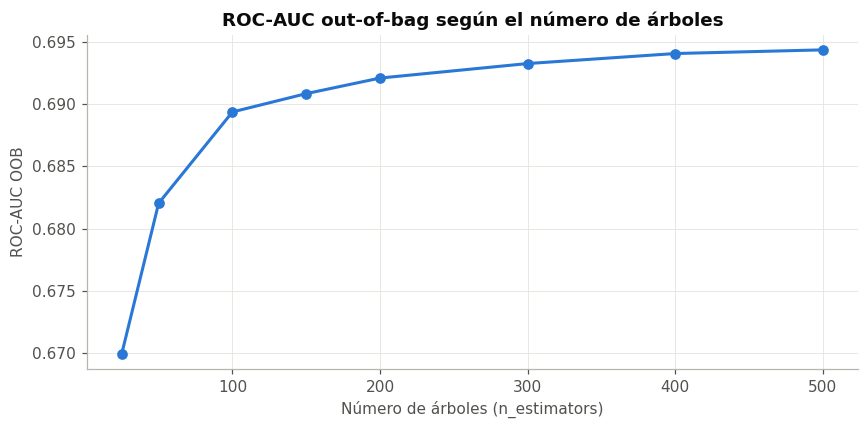

Tiempo: 0.4 min


Árboles,25,50,100,150,200,300,400,500
ROC-AUC OOB,0.67,0.682,0.6894,0.6908,0.6921,0.6933,0.6941,0.6944


In [6]:
t0 = time.time()
rf_oob = RandomForestClassifier(n_estimators=25, min_samples_leaf=50, class_weight='balanced_subsample', oob_score=True,
                                warm_start=True, n_jobs=-1, random_state=SEED)
imp = SimpleImputer(strategy='median').fit(X_train.loc[idx_aj])
X_aj_imp = imp.transform(X_train.loc[idx_aj])

n_arboles, auc_oob = [25, 50, 100, 150, 200, 300, 400, 500], []
with warnings.catch_warnings():
    warnings.simplefilter('ignore')        # con pocos árboles, algún paciente no tiene predicción OOB
    for n in n_arboles:
        rf_oob.set_params(n_estimators=n).fit(X_aj_imp, y_train.loc[idx_aj])
        prob_oob = np.nan_to_num(rf_oob.oob_decision_function_[:, 1], nan=y_train.mean())
        auc_oob.append(roc_auc_score(y_train.loc[idx_aj], prob_oob))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(n_arboles, auc_oob, marker='o', color=AZUL, linewidth=2)
ax.set(title='ROC-AUC out-of-bag según el número de árboles', xlabel='Número de árboles (n_estimators)', ylabel='ROC-AUC OOB')
plt.tight_layout()
plt.show()
print("Tiempo:", cronometro(t0))
pd.DataFrame({'Árboles': n_arboles, 'ROC-AUC OOB': np.round(auc_oob, 4)}).set_index('Árboles').T

**Cómo leerlo.** La curva sube rápido con los primeros árboles y luego se **aplana**: a partir de cierto número, agregar árboles casi no cambia el AUC (no sobreajusta, solo estabiliza el promedio y cuesta más tiempo). El número final se elige donde la curva ya es plana; en las secciones siguientes se usan 200-300 árboles para ajustar y 500 para el modelo final.

### 5.2 Complejidad de los árboles y variables por división
Las tres curvas siguientes usan la submuestra de ajuste para entrenar y el conjunto de validación para medir.

min_samples_leaf: listo (0.6 min)
max_features: listo (1.2 min)
max_depth: listo (1.6 min)


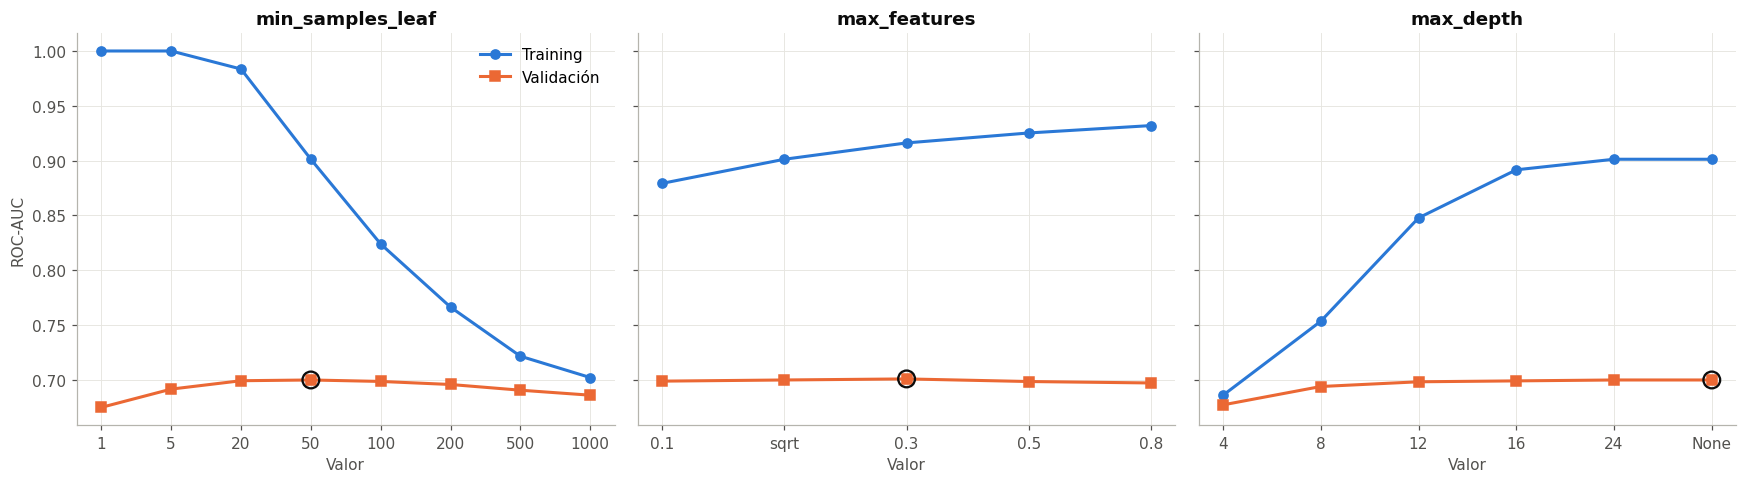


min_samples_leaf


,ROC-AUC train,ROC-AUC val,PR-AUC train,PR-AUC val,Brecha
valor,,,,,
1,1.0000,0.6746,1.0000,0.1045,0.3254
5,1.0000,0.6913,0.9999,0.1169,0.3087
20,0.9835,0.6989,0.7847,0.1207,0.2846
50,0.9011,0.6996,0.3709,0.1199,0.2015
100,0.8238,0.6983,0.2271,0.1185,0.1255
200,0.7661,0.6955,0.1663,0.1173,0.0706
500,0.7213,0.6903,0.1340,0.1131,0.0310
1000,0.7018,0.6857,0.1227,0.1105,0.0161



max_features


,ROC-AUC train,ROC-AUC val,PR-AUC train,PR-AUC val,Brecha
valor,,,,,
0.1,0.8791,0.6985,0.3262,0.1190,0.1806
sqrt,0.9011,0.6996,0.3709,0.1199,0.2015
0.3,0.9161,0.7006,0.4054,0.1200,0.2155
0.5,0.9251,0.6982,0.4275,0.1196,0.2269
0.8,0.9319,0.6969,0.4457,0.1173,0.2350



max_depth


,ROC-AUC train,ROC-AUC val,PR-AUC train,PR-AUC val,Brecha
valor,,,,,
4,0.6856,0.6769,0.1182,0.1077,0.0087
8,0.7532,0.6936,0.1824,0.1163,0.0596
12,0.8476,0.6979,0.2987,0.1194,0.1497
16,0.8915,0.6988,0.3578,0.1191,0.1927
24,0.9012,0.6996,0.3721,0.1199,0.2016
None,0.9011,0.6996,0.3709,0.1199,0.2015


In [7]:
t0 = time.time()
grillas = {
    'min_samples_leaf': [1, 5, 20, 50, 100, 200, 500, 1000],
    'max_features': [0.1, 'sqrt', 0.3, 0.5, 0.8],
    'max_depth': [4, 8, 12, 16, 24, None],
}
curvas = {}
for param, valores in grillas.items():
    filas = []
    for v in valores:
        params = {'min_samples_leaf': 50, param: v}
        r = evaluar(nuevo_rf(**params), X_train.loc[idx_aj], y_train.loc[idx_aj], X_train.loc[idx_val], y_train.loc[idx_val])
        filas.append({'valor': 'None' if v is None else str(v), **r})
    curvas[param] = pd.DataFrame(filas)
    print(f"{param}: listo ({cronometro(t0)})")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (param, t) in zip(axes, curvas.items()):
    x = np.arange(len(t))
    ax.plot(x, t['ROC-AUC train'], marker='o', color=AZUL, linewidth=2, label='Training')
    ax.plot(x, t['ROC-AUC val'], marker='s', color=NARANJA, linewidth=2, label='Validación')
    mejor = t['ROC-AUC val'].idxmax()
    ax.scatter([mejor], [t.loc[mejor, 'ROC-AUC val']], s=120, facecolors='none', edgecolors=TEXTO, linewidths=1.5, zorder=5)
    ax.set_xticks(x, t['valor'])
    ax.set(title=param, xlabel='Valor')
axes[0].set_ylabel('ROC-AUC')
axes[0].legend()
plt.tight_layout()
plt.show()

for param, t in curvas.items():
    t = t.set_index('valor').round(4)
    t['Brecha'] = (t['ROC-AUC train'] - t['ROC-AUC val']).round(4)
    print(f"\n{param}")
    display(t)

**Cómo leerlo** (el círculo marca el mejor valor en validación).
- **`min_samples_leaf`**: con hojas de 1-5 pacientes la brecha train–validación es enorme (memorización). Al exigir hojas más grandes la brecha se cierra y la validación mejora hasta un punto; con hojas demasiado grandes los árboles se vuelven muy simples y la validación vuelve a bajar.
- **`max_features`**: controla el balance entre árboles fuertes pero parecidos (valores altos) y árboles débiles pero diversos (valores bajos). Si el óptimo está en `sqrt` o 0.3, el valor por defecto ya es adecuado.
- **`max_depth`**: con `min_samples_leaf=50` fijo, la profundidad deja de importar a partir de cierto nivel porque las hojas ya están limitadas por tamaño. Por eso se prefiere regularizar con `min_samples_leaf`.

Estas curvas orientan los rangos de la búsqueda aleatoria de la sección 6.

## 6. Búsqueda aleatoria de hiperparámetros
`RandomizedSearchCV` prueba `N_ITER` combinaciones al azar con **validación cruzada estratificada de 3 folds** sobre la submuestra de ajuste. Es más eficiente que `GridSearchCV`: con 5 hiperparámetros, una grilla completa tendría cientos de combinaciones (Probst et al., 2019).

- **Métrica de selección: ROC-AUC**, la misma de `02_modelos`, para comparar. También se registra el **PR-AUC**.
- Se incluye `class_weight=None` como opción: con métricas que no dependen del umbral (ROC-AUC, PR-AUC), el bosque puede no necesitar pesos, y sin ellos sus probabilidades suelen estar mejor calibradas.
- Imputación dentro del `Pipeline`: la mediana se recalcula en cada fold, sin fuga de información.

In [8]:
t0 = time.time()
espacio = {
    'rf__max_features': ['sqrt', 0.2, 0.3, 0.5],
    'rf__min_samples_leaf': [20, 50, 100, 200, 400],
    'rf__max_depth': [None, 12, 16, 24],
    'rf__max_samples': [0.3, 0.5, 0.8, None],
    'rf__class_weight': ['balanced_subsample', None],
}
busqueda = RandomizedSearchCV(
    nuevo_rf(n_estimators=200), espacio, n_iter=N_ITER,
    scoring={'roc_auc': 'roc_auc', 'pr_auc': 'average_precision'}, refit='roc_auc',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED), random_state=SEED, n_jobs=1, return_train_score=True)
busqueda.fit(X_train.loc[idx_aj], y_train.loc[idx_aj])
print("Tiempo:", cronometro(t0))

res = pd.DataFrame(busqueda.cv_results_)
cols_param = [c for c in res.columns if c.startswith('param_rf__')]
tabla_busqueda = (res[cols_param + ['mean_train_roc_auc', 'mean_test_roc_auc', 'std_test_roc_auc', 'mean_test_pr_auc']]
                  .fillna({c: 'None' for c in cols_param})          # para que None se vea como 'None' y no como NaN
                  .rename(columns=lambda c: c.replace('param_rf__', ''))
                  .sort_values('mean_test_roc_auc', ascending=False).round(4))
tabla_busqueda.head(10)

Tiempo: 2.8 min


,min_samples_leaf,max_samples,max_features,max_depth,class_weight,mean_train_roc_auc,mean_test_roc_auc,std_test_roc_auc,mean_test_pr_auc
17,50,0.3,0.5,16,None,0.7972,0.6943,0.0055,0.1215
3,100,None,0.2,24,None,0.8100,0.6938,0.0067,0.1205
15,100,None,0.2,None,None,0.8100,0.6938,0.0067,0.1205
16,20,0.5,0.3,16,None,0.8993,0.6932,0.0062,0.1217
10,100,None,sqrt,12,None,0.7918,0.6931,0.0067,0.1200
8,50,0.8,0.2,None,balanced_subsample,0.8874,0.6930,0.0058,0.1199
2,50,0.8,0.3,24,balanced_subsample,0.8981,0.6929,0.0054,0.1191
0,20,0.8,sqrt,24,None,0.9397,0.6921,0.0073,0.1207
18,50,0.3,0.2,24,balanced_subsample,0.7983,0.6919,0.0063,0.1186
6,200,None,0.5,12,balanced_subsample,0.7808,0.6916,0.0062,0.1189


Mejor combinación: {'min_samples_leaf': 50, 'max_samples': 0.3, 'max_features': 0.5, 'max_depth': 16, 'class_weight': None}
ROC-AUC CV: 0.6943 ± 0.0055


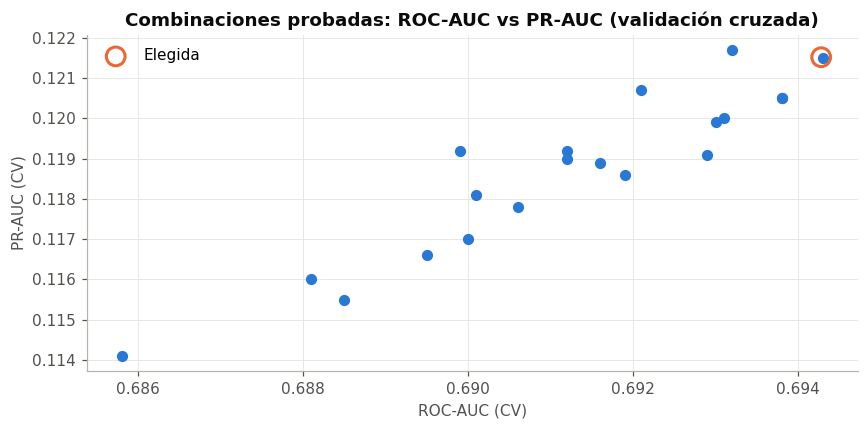

In [9]:
mejores = {k.replace('rf__', ''): v for k, v in busqueda.best_params_.items()}
print("Mejor combinación:", mejores)
print(f"ROC-AUC CV: {busqueda.best_score_:.4f} ± {res.loc[busqueda.best_index_, 'std_test_roc_auc']:.4f}")

# ¿Cuánto cambia el desempeño entre combinaciones? Si casi todas empatan, el bosque es poco sensible a los hiperparámetros.
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(tabla_busqueda['mean_test_roc_auc'], tabla_busqueda['mean_test_pr_auc'], color=AZUL, s=40)
ax.scatter([busqueda.best_score_], [res.loc[busqueda.best_index_, 'mean_test_pr_auc']], s=150, facecolors='none',
           edgecolors=NARANJA, linewidths=2, label='Elegida')
ax.set(title='Combinaciones probadas: ROC-AUC vs PR-AUC (validación cruzada)', xlabel='ROC-AUC (CV)', ylabel='PR-AUC (CV)')
ax.legend()
plt.tight_layout()
plt.show()

**Cómo leerlo.** La tabla ordena las combinaciones por ROC-AUC en validación cruzada. Conviene revisar tres cosas para justificar la elección en el informe:
1. **La distancia entre la mejor y las siguientes.** Si las diferencias son menores que la desviación estándar entre folds, varias combinaciones son equivalentes y se puede preferir la más simple o rápida.
2. **La brecha train–CV** (`mean_train_roc_auc` − `mean_test_roc_auc`): cuanto menor, menos sobreajuste.
3. **Si `class_weight=None` aparece entre las mejores**: confirmaría que, para ordenar pacientes por riesgo, el bosque no necesita los pesos de clase.

## 7. Modelo final

### 7.1 Entrenamiento con todo el train
Se usa la mejor combinación con `N_ARBOLES_FINAL` árboles y `oob_score=True`, entrenada con **todo** el conjunto de entrenamiento.

In [10]:
t0 = time.time()
rf_final = nuevo_rf(**{**mejores, 'n_estimators': N_ARBOLES_FINAL, 'oob_score': True})
rf_final.fit(X_train, y_train)
print("Tiempo de entrenamiento:", cronometro(t0))

prob_oob = rf_final['rf'].oob_decision_function_[:, 1]
prob_test_rf = rf_final.predict_proba(X_test)[:, 1]
print(f"ROC-AUC OOB (train): {roc_auc_score(y_train, prob_oob):.4f} | ROC-AUC test: {roc_auc_score(y_test, prob_test_rf):.4f}")

Tiempo de entrenamiento: 0.9 min
ROC-AUC OOB (train): 0.7083 | ROC-AUC test: 0.7050


**Cómo leerlo.** El AUC OOB es una estimación honesta del desempeño calculada solo con train. Si el AUC de test es parecido, el modelo generaliza como se esperaba.

### 7.2 Elección del umbral de decisión
Con el umbral por defecto (0.5) el modelo clasifica como "en riesgo" a quien tenga probabilidad ≥ 0.5. Con clases desbalanceadas ese umbral rara vez es el adecuado. El umbral se elige con las predicciones **OOB** de train (maximizando F1), **nunca con el test**, para no contaminar la evaluación.

In [11]:
precision_c, recall_c, umbrales = precision_recall_curve(y_train, prob_oob)
f1_c = 2 * precision_c * recall_c / np.clip(precision_c + recall_c, 1e-12, None)
UMBRAL = float(umbrales[np.argmax(f1_c[:-1])])
print(f"Umbral elegido con OOB (máximo F1): {UMBRAL:.3f}")

def metricas(nombre, y_true, prob, umbral):
    pred = (prob >= umbral).astype(int)
    return {'Modelo': nombre, 'Umbral': round(umbral, 3), 'ROC-AUC': roc_auc_score(y_true, prob),
            'PR-AUC': average_precision_score(y_true, prob), 'Brier': brier_score_loss(y_true, prob),
            'Precision': precision_score(y_true, pred, zero_division=0), 'Recall': recall_score(y_true, pred),
            'F1': f1_score(y_true, pred), '% marcados en riesgo': pred.mean() * 100}

tabla_rf = pd.DataFrame([metricas('RF (umbral 0.5)', y_test, prob_test_rf, 0.5),
                         metricas('RF (umbral OOB)', y_test, prob_test_rf, UMBRAL)]).set_index('Modelo').round(4)
tabla_rf

Umbral elegido con OOB (máximo F1): 0.101


,Umbral,ROC-AUC,PR-AUC,Brier,Precision,Recall,F1,% marcados en riesgo
Modelo,,,,,,,,
RF (umbral 0.5),0.500,0.705,0.1241,0.0512,0.0000,0.0000,0.0000,0.0000
RF (umbral OOB),0.101,0.705,0.1241,0.0512,0.1363,0.3201,0.1912,13.1622


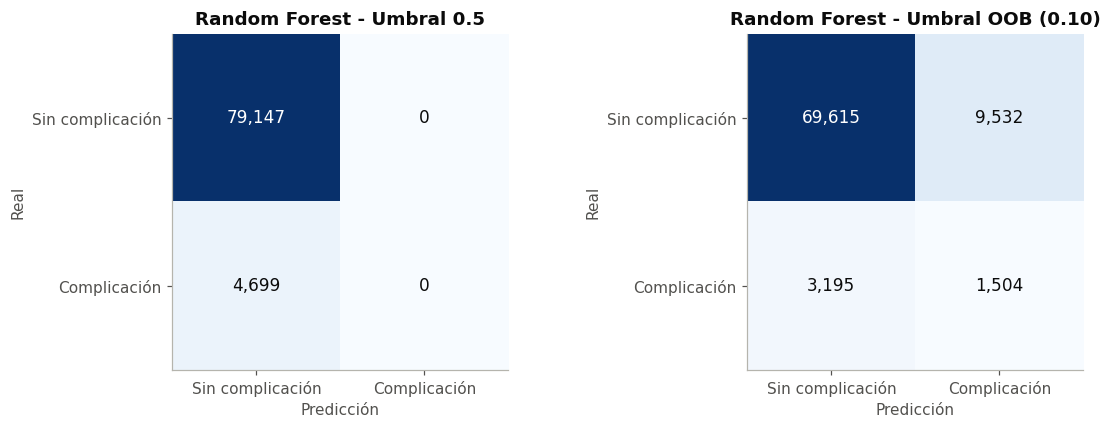

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
etiquetas = ['Sin complicación', 'Complicación']
for ax, (titulo, umbral) in zip(axes, [('Umbral 0.5', 0.5), (f'Umbral OOB ({UMBRAL:.2f})', UMBRAL)]):
    cm = confusion_matrix(y_test, (prob_test_rf >= umbral).astype(int))
    ax.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else TEXTO, fontsize=11)
    ax.set_xticks([0, 1], etiquetas); ax.set_yticks([0, 1], etiquetas)
    ax.set(title=f'Random Forest - {titulo}', xlabel='Predicción', ylabel='Real')
    ax.grid(False)
plt.tight_layout()
plt.show()

**Cómo leerlo.** El ROC-AUC, el PR-AUC y el Brier no dependen del umbral; precision, recall y F1 sí. Si la búsqueda eligió `class_weight=None`, las probabilidades del bosque quedan cerca de la prevalencia real (≈5%) y con el umbral 0.5 **no marca a ningún paciente** (recall = 0, igual que KNN en `02_modelos`): por eso el umbral elegido con OOB es imprescindible. Al bajar el umbral el modelo detecta más pacientes que se complicarán (sube el recall) a costa de más falsas alarmas (baja la precision). En un contexto de prevención, el umbral final debería fijarse según cuántos pacientes puede seguir el sistema de salud; el máximo F1 es solo un punto de partida razonable.

## 8. Comparación con la regresión logística
Se vuelve a entrenar el mejor modelo de `02_modelos` (regresión logística, `lbfgs`, C = 0.01, `class_weight='balanced'`) sobre **las mismas variables y la misma partición**, para compararlo en igualdad de condiciones. Su umbral también se elige sin tocar el test (validación cruzada de 5 folds en train).

In [13]:
from sklearn.model_selection import cross_val_predict

rl = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()),
               ('modelo', LogisticRegression(C=0.01, class_weight='balanced', max_iter=1000, random_state=SEED))])
prob_cv_rl = cross_val_predict(rl, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method='predict_proba')[:, 1]
p_c, r_c, u_c = precision_recall_curve(y_train, prob_cv_rl)
UMBRAL_RL = float(u_c[np.argmax((2 * p_c * r_c / np.clip(p_c + r_c, 1e-12, None))[:-1])])
rl.fit(X_train, y_train)
prob_test_rl = rl.predict_proba(X_test)[:, 1]

comparacion = pd.DataFrame([metricas('Regresión logística', y_test, prob_test_rl, UMBRAL_RL),
                            metricas('Random Forest', y_test, prob_test_rf, UMBRAL)]).set_index('Modelo').round(4)
comparacion

,Umbral,ROC-AUC,PR-AUC,Brier,Precision,Recall,F1,% marcados en riesgo
Modelo,,,,,,,,
Regresión logística,0.633,0.6924,0.1162,0.2211,0.1282,0.3247,0.1838,14.1986
Random Forest,0.101,0.7050,0.1241,0.0512,0.1363,0.3201,0.1912,13.1622


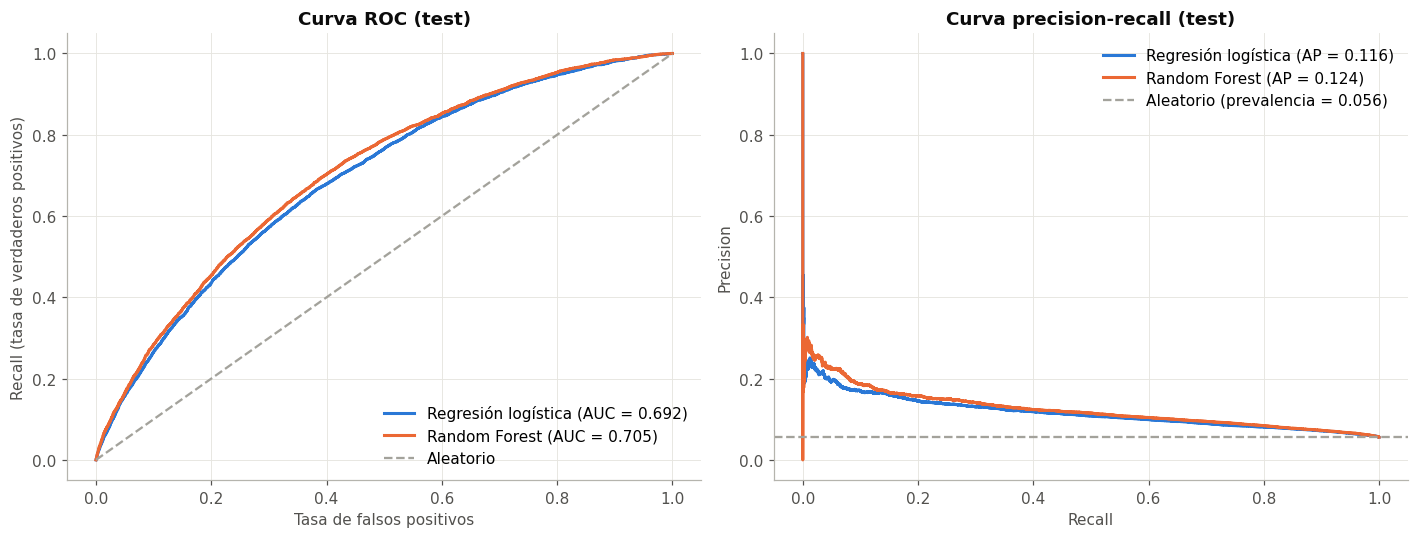

In [14]:
prevalencia = y_test.mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for nombre, prob, color in [('Regresión logística', prob_test_rl, AZUL), ('Random Forest', prob_test_rf, NARANJA)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[0].plot(fpr, tpr, color=color, linewidth=2, label=f'{nombre} (AUC = {roc_auc_score(y_test, prob):.3f})')
    prec, rec, _ = precision_recall_curve(y_test, prob)
    axes[1].plot(rec, prec, color=color, linewidth=2, label=f'{nombre} (AP = {average_precision_score(y_test, prob):.3f})')
axes[0].plot([0, 1], [0, 1], color=GRIS, linestyle='--', label='Aleatorio')
axes[0].set(title='Curva ROC (test)', xlabel='Tasa de falsos positivos', ylabel='Recall (tasa de verdaderos positivos)')
axes[1].axhline(prevalencia, color=GRIS, linestyle='--', label=f'Aleatorio (prevalencia = {prevalencia:.3f})')
axes[1].set(title='Curva precision-recall (test)', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.legend(loc='lower right' if ax is axes[0] else 'upper right')
plt.tight_layout()
plt.show()

**Cómo leerlo.**
- La **curva ROC** mide qué tan bien cada modelo **ordena** a los pacientes por riesgo. Si las curvas casi se superponen, la ganancia del bosque es pequeña.
- La **curva precision-recall** es más exigente con el desbalance: muestra, para cada nivel de detección (recall), qué fracción de los pacientes marcados realmente se complica. La línea gris es lo que lograría un modelo al azar (la prevalencia, ≈5.6%).
- Para el informe: si el bosque mejora poco sobre la regresión logística, es un resultado válido e informativo. Con datos administrativos agregados por paciente, gran parte de la señal es casi lineal (edad, antecedentes, uso de servicios) y la regresión logística ya la captura. Una ganancia clara indicaría **interacciones o efectos no lineales** que la logística no modela.

### 8.1 ¿La diferencia es significativa? (bootstrap pareado)
La diferencia entre el bosque y la regresión logística es de centésimas. Para saber si es real, se remuestrea el test con reemplazo 500 veces y en cada muestra se calcula el AUC de **ambos modelos sobre los mismos pacientes**. El intervalo del 95% de la diferencia va del percentil 2.5 al 97.5: si no incluye el 0, el bosque es significativamente mejor.

,Media,IC 95% inferior,IC 95% superior
ROC-AUC RF,0.7049,0.6982,0.7117
ROC-AUC RL,0.6924,0.6854,0.6996
PR-AUC RF,0.1243,0.1176,0.1309
PR-AUC RL,0.1163,0.1103,0.1218
Δ ROC-AUC (RF − RL),0.0125,0.0087,0.0162
Δ PR-AUC (RF − RL),0.0079,0.0041,0.0114


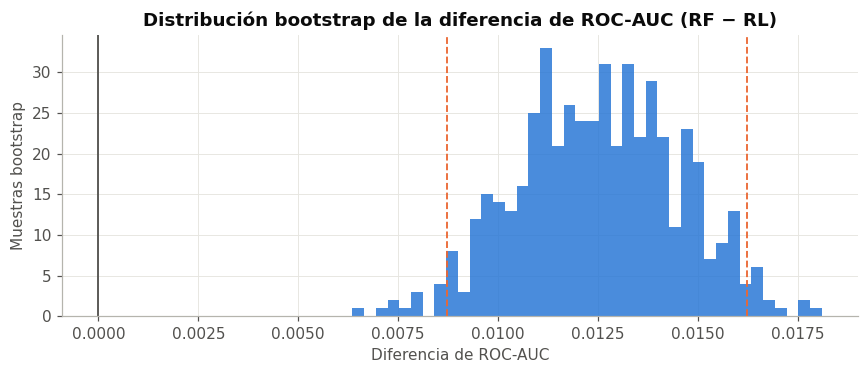

In [15]:
rng = np.random.default_rng(SEED)
y_arr = y_test.values
filas = []
for _ in range(500):
    b = rng.integers(0, len(y_arr), len(y_arr))
    filas.append({'ROC-AUC RF': roc_auc_score(y_arr[b], prob_test_rf[b]), 'ROC-AUC RL': roc_auc_score(y_arr[b], prob_test_rl[b]),
                  'PR-AUC RF': average_precision_score(y_arr[b], prob_test_rf[b]), 'PR-AUC RL': average_precision_score(y_arr[b], prob_test_rl[b])})
boot = pd.DataFrame(filas)
boot['Δ ROC-AUC (RF − RL)'] = boot['ROC-AUC RF'] - boot['ROC-AUC RL']
boot['Δ PR-AUC (RF − RL)'] = boot['PR-AUC RF'] - boot['PR-AUC RL']

ic_boot = pd.DataFrame({'Media': boot.mean(), 'IC 95% inferior': boot.quantile(0.025), 'IC 95% superior': boot.quantile(0.975)})
display(ic_boot.round(4))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(boot['Δ ROC-AUC (RF − RL)'], bins=40, color=AZUL, alpha=0.85)
ax.axvline(0, color=TEXTO_2, linewidth=1.2)
for q in (0.025, 0.975):
    ax.axvline(boot['Δ ROC-AUC (RF − RL)'].quantile(q), color=NARANJA, linestyle='--', linewidth=1.2)
ax.set(title='Distribución bootstrap de la diferencia de ROC-AUC (RF − RL)', xlabel='Diferencia de ROC-AUC', ylabel='Muestras bootstrap')
plt.tight_layout()
plt.show()

**Cómo leerlo.** Las líneas naranjas son los límites del intervalo del 95%. Si toda la distribución está a la derecha del 0, el bosque ordena mejor a los pacientes que la regresión logística en prácticamente cualquier muestra de test: la mejora es real, aunque sea pequeña. Para el informe se reporta como "ROC-AUC 0.705 vs 0.692; diferencia +0.013 (IC 95%: a, b)".

### 8.2 ¿Cuántas complicaciones captura el grupo de mayor riesgo?
Un programa de seguimiento del SIS tiene capacidad para un **porcentaje fijo** de pacientes. La pregunta útil es: *si se sigue al X% de pacientes con mayor riesgo, ¿qué porcentaje de las complicaciones se concentra en ellos?* Como el porcentaje se fija de antemano (no se optimiza con el test), la evaluación no tiene fuga de información. El **lift** indica cuántas veces más complicaciones hay en ese grupo que en uno elegido al azar.

Regresión logística                      \
      Complicaciones capturadas (%) Precision (%)  Lift   
Top %                                                     
5                             14.54         16.29  2.91   
10                            24.62         13.80  2.46   
20                            41.67         11.68  2.08   
30                            55.39         10.35  1.85   

                      Random Forest                      
      Complicaciones capturadas (%) Precision (%)  Lift  
Top %                                                    
5                             14.85         16.65  2.97  
10                            26.32         14.75  2.63  
20                            43.37         12.15  2.17  
30                            57.12         10.67  1.90

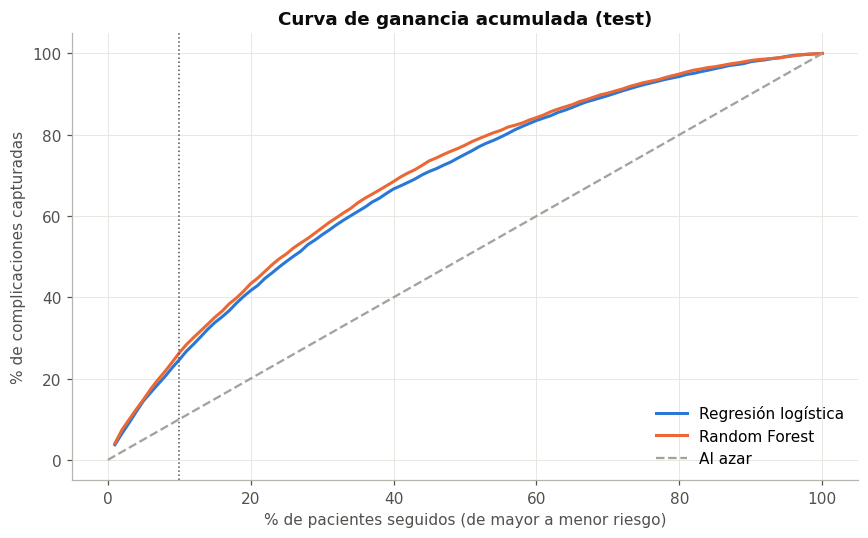

In [16]:
def captura(y_true, prob, porcentajes=(5, 10, 20, 30)):
    y_ord = np.asarray(y_true)[np.argsort(-prob)]
    filas = []
    for p in porcentajes:
        n = int(len(y_ord) * p / 100)
        filas.append({'Top %': p, 'Complicaciones capturadas (%)': y_ord[:n].sum() / y_ord.sum() * 100,
                      'Precision (%)': y_ord[:n].mean() * 100, 'Lift': y_ord[:n].mean() / y_ord.mean()})
    return pd.DataFrame(filas).set_index('Top %')

tabla_captura = pd.concat({'Regresión logística': captura(y_test, prob_test_rl), 'Random Forest': captura(y_test, prob_test_rf)}, axis=1)
display(tabla_captura.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
pct = np.arange(1, 101)
for nombre, prob, color in [('Regresión logística', prob_test_rl, AZUL), ('Random Forest', prob_test_rf, NARANJA)]:
    y_ord = y_test.values[np.argsort(-prob)]
    acumulado = np.cumsum(y_ord) / y_ord.sum() * 100
    ax.plot(pct, acumulado[(pct * len(y_ord) // 100) - 1], color=color, linewidth=2, label=nombre)
ax.plot([0, 100], [0, 100], color=GRIS, linestyle='--', label='Al azar')
ax.axvline(10, color=TEXTO_2, linestyle=':', linewidth=1)
ax.set(title='Curva de ganancia acumulada (test)', xlabel='% de pacientes seguidos (de mayor a menor riesgo)',
       ylabel='% de complicaciones capturadas')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Cómo leerlo.** Es la forma más directa de explicar el valor del modelo a alguien no técnico: "si el SIS sigue al 10% de hipertensos que el modelo marca como de mayor riesgo, concentra el X% de las complicaciones del año siguiente, Y veces más que eligiendo al azar". Con el umbral de máximo F1 de la sección 7.2 el modelo marca a ≈13% de los pacientes, así que ese punto queda entre las filas del 10% y el 20%.

## 9. Calibración: ¿las probabilidades son creíbles?
Un modelo de riesgo no solo debe ordenar bien: si dice "10% de riesgo", aproximadamente 10 de cada 100 pacientes así deberían complicarse. La curva de calibración agrupa a los pacientes de test en 10 grupos según su probabilidad predicha y compara la media predicha con la proporción real de complicaciones. La diagonal es la calibración perfecta.

Para que la comparación sea justa se agrega una **regresión logística sin pesos de clase**: la del modelo de `02_modelos` usa `class_weight='balanced'`, que distorsiona sus probabilidades a propósito, mientras que el bosque elegido no usa pesos.

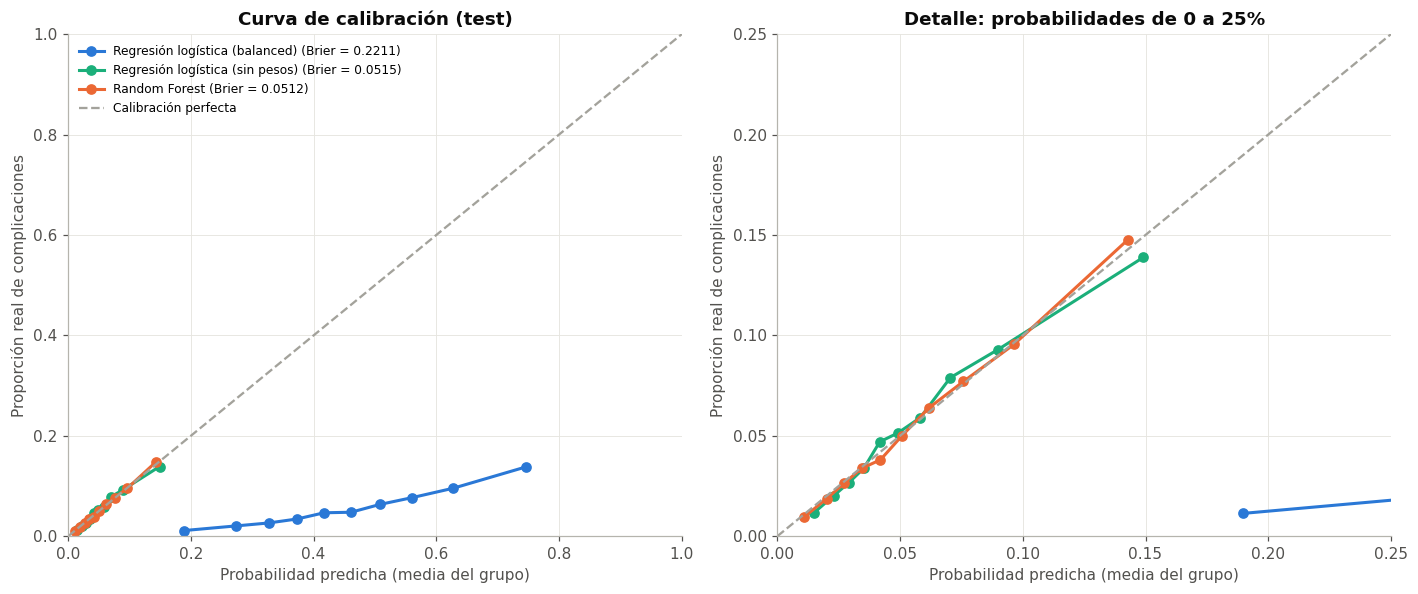

,ROC-AUC,Brier,Probabilidad media predicha,Tasa real
Regresión logística (balanced),0.6924,0.2211,0.4483,0.056
Regresión logística (sin pesos),0.6918,0.0515,0.0561,0.056
Random Forest,0.7050,0.0512,0.0562,0.056


In [17]:
rl_sin_pesos = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()),
                         ('modelo', LogisticRegression(C=0.01, max_iter=1000, random_state=SEED))])
rl_sin_pesos.fit(X_train, y_train)
prob_test_rl_sp = rl_sin_pesos.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
modelos_cal = [('Regresión logística (balanced)', prob_test_rl, AZUL), ('Regresión logística (sin pesos)', prob_test_rl_sp, AQUA),
               ('Random Forest', prob_test_rf, NARANJA)]
for ax, limite in zip(axes, [1.0, 0.25]):
    for nombre, prob, color in modelos_cal:
        real, predicha = calibration_curve(y_test, prob, n_bins=10, strategy='quantile')
        ax.plot(predicha, real, marker='o', color=color, linewidth=2, label=f'{nombre} (Brier = {brier_score_loss(y_test, prob):.4f})')
    ax.plot([0, limite], [0, limite], color=GRIS, linestyle='--', label='Calibración perfecta')
    ax.set_xlim(0, limite); ax.set_ylim(0, limite)
    ax.set(xlabel='Probabilidad predicha (media del grupo)', ylabel='Proporción real de complicaciones')
axes[0].set_title('Curva de calibración (test)')
axes[1].set_title('Detalle: probabilidades de 0 a 25%')
axes[0].legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

pd.DataFrame({'ROC-AUC': {n: roc_auc_score(y_test, p) for n, p, _ in modelos_cal},
              'Brier': {n: brier_score_loss(y_test, p) for n, p, _ in modelos_cal},
              'Probabilidad media predicha': {n: p.mean() for n, p, _ in modelos_cal}}).assign(**{'Tasa real': y_test.mean()}).round(4)

**Cómo leerlo.** Los modelos entrenados con pesos de clase (`balanced`) **sobrestiman** el riesgo: sus puntos quedan por debajo de la diagonal, porque los pesos los hacen "ver" muchos más positivos de los que hay (van den Goorbergh et al., 2022). La regresión logística **sin pesos** tiene prácticamente el mismo ROC-AUC que la versión con pesos (los pesos no mejoran la capacidad de ordenar) y sus probabilidades quedan cerca de la diagonal, como las del bosque. La conclusión para el informe es que **la mala calibración era efecto de los pesos de clase, no del tipo de modelo**: si el objetivo es comunicar riesgos individuales ("este paciente tiene 12% de riesgo"), conviene entrenar sin pesos y ajustar después el umbral, en vez de usar `class_weight='balanced'`.

## 10. ¿Qué variables usa el modelo?
Se comparan dos medidas de importancia:
- **MDI** (*mean decrease in impurity*, `feature_importances_`): cuánto reduce cada variable la impureza en las divisiones de todos los árboles. Es gratis de calcular, pero se mide en **train** y favorece a las variables continuas con muchos valores distintos (gasto, altitud) frente a las binarias (diabetes, sexo).
- **Importancia por permutación**: cuánto cae el ROC-AUC en **test** al desordenar al azar los valores de una variable. Es más lenta, pero mide lo que la variable aporta a predecir pacientes nuevos. Se calcula sobre una submuestra estratificada del test.

Tiempo: 0.7 min


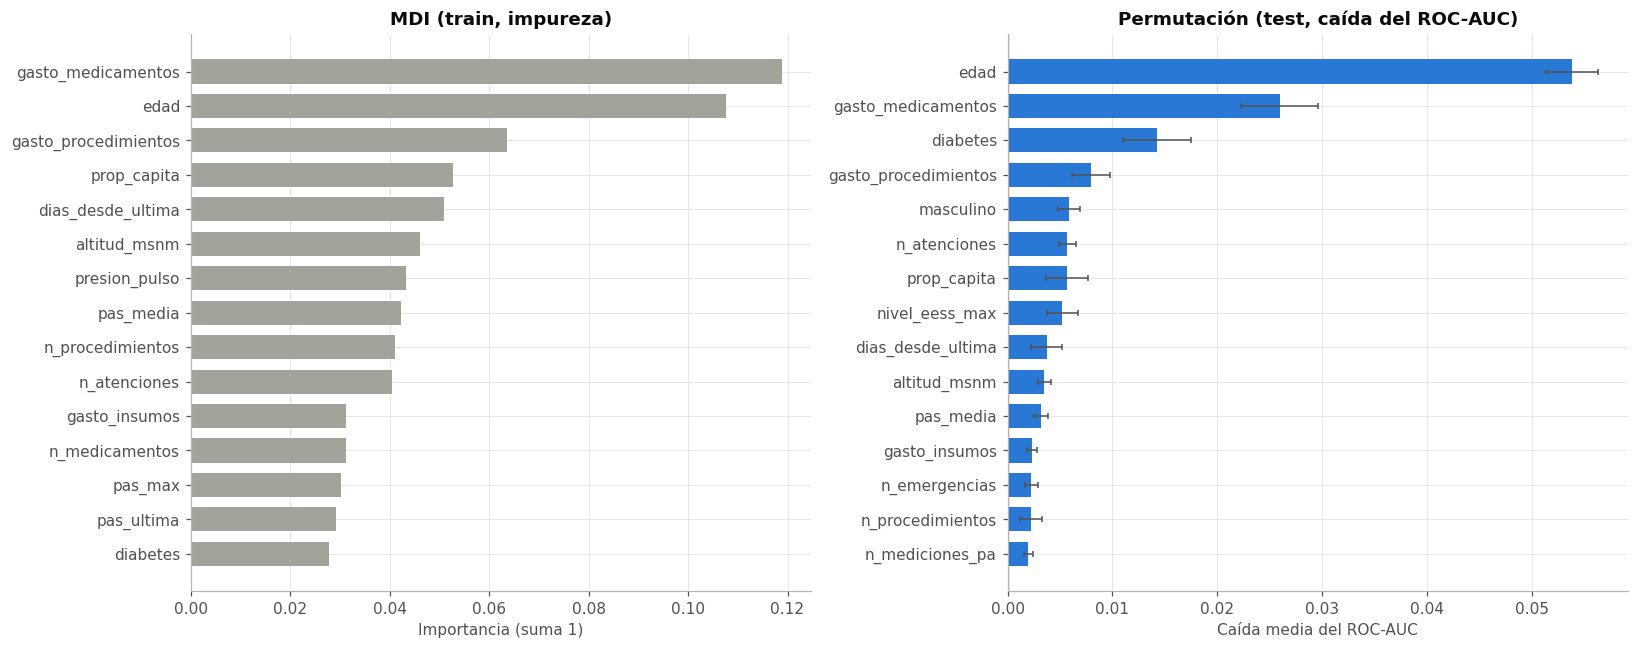

,MDI,Permutación,Ranking MDI,Ranking permutación
edad,0.1076,0.0539,2,1
gasto_medicamentos,0.1188,0.0260,1,2
diabetes,0.0278,0.0143,15,3
gasto_procedimientos,0.0635,0.0080,3,4
masculino,0.0165,0.0058,24,5
n_atenciones,0.0405,0.0057,10,6
prop_capita,0.0528,0.0056,4,7
nivel_eess_max,0.0183,0.0052,23,8
dias_desde_ultima,0.0509,0.0037,5,9
altitud_msnm,0.0461,0.0035,6,10


In [18]:
t0 = time.time()
mdi = pd.Series(rf_final['rf'].feature_importances_, index=X.columns)

n_perm = min(N_PERMUTACION, len(X_test))
idx_perm = X_test.index if n_perm == len(X_test) else train_test_split(X_test.index, train_size=n_perm, random_state=SEED, stratify=y_test)[0]
perm = permutation_importance(rf_final, X_test.loc[idx_perm], y_test.loc[idx_perm], scoring='roc_auc',
                              n_repeats=5, random_state=SEED, n_jobs=1)
perm_media = pd.Series(perm.importances_mean, index=X.columns)
perm_std = pd.Series(perm.importances_std, index=X.columns)
print("Tiempo:", cronometro(t0))

top = 15
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
orden = mdi.sort_values().tail(top)
axes[0].barh(orden.index, orden.values, color=GRIS, height=0.7)
axes[0].set(title='MDI (train, impureza)', xlabel='Importancia (suma 1)')
orden = perm_media.sort_values().tail(top)
axes[1].barh(orden.index, orden.values, xerr=perm_std[orden.index], color=AZUL, height=0.7,
             error_kw={'ecolor': TEXTO_2, 'elinewidth': 1, 'capsize': 2})
axes[1].axvline(0, color=TEXTO_2, linewidth=0.8)
axes[1].set(title='Permutación (test, caída del ROC-AUC)', xlabel='Caída media del ROC-AUC')
plt.tight_layout()
plt.show()

pd.DataFrame({'MDI': mdi, 'Permutación': perm_media, 'Ranking MDI': mdi.rank(ascending=False).astype(int),
              'Ranking permutación': perm_media.rank(ascending=False).astype(int)}).sort_values('Permutación', ascending=False).round(4).head(20)

**Cómo leerlo.**
- Las variables que están arriba en **ambos** rankings son las señales robustas del modelo.
- Una variable alta en MDI pero baja en permutación (típicamente `gasto_*`, `altitud_msnm` o `dias_desde_ultima`) es una variable continua que el bosque usa mucho para dividir, pero que aporta poco a predecir pacientes nuevos.
- Una importancia por permutación cercana a 0 (o negativa) indica que la variable no aporta información **adicional** a las demás; no necesariamente que no esté relacionada con `y`. Si dos variables están correlacionadas (p. ej. `n_atenciones` y `n_diagnosticos`), al desordenar una el modelo usa la otra y ambas parecen poco importantes.
- Comparar con los coeficientes de la regresión logística en `02_modelos` y con las tasas por grupo del preprocesamiento (edad, fibrilación auricular, cardiopatía hipertensiva, etc.).

## 11. ¿Aportan las variables de gasto?
El EDA mostró que el 100% de los consumos por cápita tiene valor 0: `gasto_*` refleja en buena parte **cómo se financia el establecimiento**, no cuánto consumió el paciente. Para saber si estas variables aportan, se reentrena el modelo final **sin** ellas y se compara en test.

In [19]:
t0 = time.time()
cols_gasto = [c for c in X.columns if c.startswith('gasto_')]
rf_sin_gasto = nuevo_rf(**{**mejores, 'n_estimators': N_ARBOLES_FINAL})
rf_sin_gasto.fit(X_train.drop(columns=cols_gasto), y_train)
prob_sin_gasto = rf_sin_gasto.predict_proba(X_test.drop(columns=cols_gasto))[:, 1]
print("Tiempo:", cronometro(t0))

pd.DataFrame({
    'Variables': [X.shape[1], X.shape[1] - len(cols_gasto)],
    'ROC-AUC test': [roc_auc_score(y_test, prob_test_rf), roc_auc_score(y_test, prob_sin_gasto)],
    'PR-AUC test': [average_precision_score(y_test, prob_test_rf), average_precision_score(y_test, prob_sin_gasto)],
}, index=['Con gasto', f'Sin gasto ({", ".join(cols_gasto)})']).round(4)

Tiempo: 0.4 min


,Variables,ROC-AUC test,PR-AUC test
Con gasto,34,0.7050,0.1241
"Sin gasto (gasto_medicamentos, gasto_procedimientos, gasto_insumos)",31,0.7035,0.1236


**Cómo leerlo.** Si el desempeño casi no cambia (diferencias de pocas milésimas), las variables de gasto son prescindibles: el modelo sin ellas es más simple y no depende de una variable sesgada por el financiamiento. Si el desempeño cae claramente, el gasto aporta información que los conteos (`n_*`) no capturan, y conviene mantenerlo junto con `prop_capita`.

### 11.1 ¿Riesgo clínico o uso del sistema de salud?
Entre las variables más importantes hay varias que no describen el estado clínico del paciente sino **cómo y dónde se atiende** (`prop_capita`, `nivel_eess_max`, `n_atenciones`, `dias_desde_ultima`, gasto). Un paciente atendido en un hospital tiene más oportunidades de que se le **registre** un diagnóstico de insuficiencia cardíaca o enfermedad renal (sesgo de detección). Se reentrena el bosque con los mismos hiperparámetros usando solo cada grupo de variables.

In [20]:
t0 = time.time()
CLINICAS = ['edad', 'masculino', 'pas_media', 'pas_max', 'pad_max', 'presion_pulso', 'presion_pulso_max', 'prop_pa_alta',
            'pas_ultima', 'sin_medicion_pa', 'diabetes', 'dislipidemia', 'obesidad', 'fib_auricular', 'cardiopatia',
            'hta_cardiaca', 'n_comorbilidades']
CLINICAS = [c for c in CLINICAS if c in X.columns]
USO_SISTEMA = [c for c in X.columns if c not in CLINICAS]
print("Clínicas y demográficas:", CLINICAS)
print("Uso del sistema de salud y ubicación del establecimiento:", USO_SISTEMA)

resultados_grupos = {'Todas las variables': (X.shape[1], prob_test_rf), 'Sin gasto': (X.shape[1] - len(cols_gasto), prob_sin_gasto)}
for nombre, columnas in [('Solo clínicas y demográficas', CLINICAS), ('Solo uso del sistema', USO_SISTEMA)]:
    modelo = nuevo_rf(**{**mejores, 'n_estimators': 300})
    modelo.fit(X_train[columnas], y_train)
    resultados_grupos[nombre] = (len(columnas), modelo.predict_proba(X_test[columnas])[:, 1])
print("Tiempo:", cronometro(t0))

tabla_grupos = pd.DataFrame({nombre: {'Variables': n, 'ROC-AUC test': roc_auc_score(y_test, p), 'PR-AUC test': average_precision_score(y_test, p),
                                      '% complicaciones en el top 10%': captura(y_test, p).loc[10, 'Complicaciones capturadas (%)']}
                             for nombre, (n, p) in resultados_grupos.items()}).T
tabla_grupos['Variables'] = tabla_grupos['Variables'].astype(int)
tabla_grupos.round(4)

Clínicas y demográficas: ['edad', 'masculino', 'pas_media', 'pas_max', 'pad_max', 'presion_pulso', 'presion_pulso_max', 'prop_pa_alta', 'pas_ultima', 'sin_medicion_pa', 'diabetes', 'dislipidemia', 'obesidad', 'fib_auricular', 'cardiopatia', 'hta_cardiaca', 'n_comorbilidades']
Uso del sistema de salud y ubicación del establecimiento: ['es_lima_frecuente', 'altitud_msnm', 'n_atenciones', 'n_emergencias', 'n_hospitalizaciones', 'n_mediciones_pa', 'prop_capita', 'nivel_eess_max', 'dias_desde_ultima', 'n_diagnosticos', 'n_medicamentos', 'gasto_medicamentos', 'n_procedimientos', 'gasto_procedimientos', 'n_insumos', 'gasto_insumos', 'polifarmacia']
Tiempo: 0.4 min


,Variables,ROC-AUC test,PR-AUC test,% complicaciones en el top 10%
Todas las variables,34,0.7050,0.1241,26.3247
Sin gasto,31,0.7035,0.1236,26.0055
Solo clínicas y demográficas,17,0.6587,0.1049,22.1324
Solo uso del sistema,17,0.6570,0.1068,22.7282


**Cómo leerlo.**
- Si el modelo **solo clínico** pierde poco frente al completo, el riesgo se explica sobre todo por las características del paciente (edad, sexo, presión, comorbilidades).
- Si el modelo **solo de uso del sistema** se acerca al completo, una parte importante de la predicción es el acceso a la atención y la probabilidad de que el diagnóstico se registre. El uso del sistema también refleja gravedad (un paciente más enfermo va más al hospital), así que no invalida el modelo, pero es una **limitación** que debe declararse en el informe.
- Lo más probable es que ambos grupos aporten información complementaria y que el modelo completo sea el mejor.

## 12. Guardar resultados

In [21]:
resumen = pd.concat([comparacion, tabla_rf.loc[['RF (umbral 0.5)']]])
resumen.to_csv(RUTA_SALIDA / 'resultados_random_forest.csv')
# Probabilidades de test por paciente: 05_gru.ipynb las usa para comparar la GRU con el bosque sobre los mismos pacientes
pd.DataFrame({'paciente': X_test.index, 'y': y_test.values, 'prob_rf': prob_test_rf, 'prob_rl': prob_test_rl,
              'prob_rl_sin_pesos': prob_test_rl_sp}).to_csv(RUTA_SALIDA / 'predicciones_test_rf_rl.csv', index=False)
pd.Series(mejores).to_csv(RUTA_SALIDA / 'mejores_hiperparametros_rf.csv', header=['valor'])
print("Guardado en:", RUTA_SALIDA)
resumen

Guardado en: C:\Users\ROG STRIX\Desktop\IA\ProyectoIA\data\processed


,Umbral,ROC-AUC,PR-AUC,Brier,Precision,Recall,F1,% marcados en riesgo
Modelo,,,,,,,,
Regresión logística,0.633,0.6924,0.1162,0.2211,0.1282,0.3247,0.1838,14.1986
Random Forest,0.101,0.7050,0.1241,0.0512,0.1363,0.3201,0.1912,13.1622
RF (umbral 0.5),0.500,0.7050,0.1241,0.0512,0.0000,0.0000,0.0000,0.0000


## 13. Conclusiones
*Cifras de la ejecución del 17-nov (419,226 pacientes, 34 variables, 5.60% de complicaciones; misma partición que `02_modelos`). Las de las secciones 8.1, 8.2, 9 y 11.1 se leen en sus tablas.*

1. **Ajuste de hiperparámetros.** El bosque por defecto memoriza el entrenamiento (ROC-AUC train 1.00, validación 0.663). Casi toda la mejora vino de **regularizar el tamaño de las hojas**: con `min_samples_leaf` entre 20 y 100 la validación sube a ≈0.70. `max_features` cambia el AUC en menos de 0.004 y `max_depth` deja de importar a partir de 16. La curva OOB se aplana desde 200-300 árboles. En la búsqueda aleatoria, las 10 mejores combinaciones quedan a menos de 0.003 de AUC entre sí, por debajo de la desviación entre folds (0.006): **el bosque es poco sensible a los hiperparámetros** una vez regularizado, como reportan Probst et al. (2019).
2. **Modelo elegido:** `min_samples_leaf=50`, `max_samples=0.3`, `max_features=0.5`, `max_depth=16`, `class_weight=None`, 500 árboles. Las 5 mejores combinaciones de la búsqueda no usan pesos de clase: para ordenar pacientes por riesgo, el bosque no los necesita.
3. **Desempeño.** ROC-AUC test **0.705** (OOB 0.708: no hay sobreajuste) frente a 0.692 de la regresión logística; PR-AUC 0.124 frente a 0.116 (un modelo al azar obtendría 0.056). Es el mejor modelo del proyecto, aunque la mejora es modesta; su significancia se evalúa con el bootstrap pareado de la sección 8.1.
4. **Uso práctico.** Con el umbral elegido con OOB (0.101) el bosque marca al 13.2% de los pacientes y detecta al 32.0% de los que se complicarán, con una precision de 13.6% (2.4 veces la prevalencia): ≈6 falsas alarmas por cada acierto. La tabla de captura de la sección 8.2 permite fijar el punto de operación según cuántos pacientes puede seguir el sistema.
5. **Calibración.** El bosque sin pesos está bien calibrado (Brier 0.051; probabilidades predichas de 0 a ≈15%, realistas para una prevalencia de 5.6%). La regresión logística con `class_weight='balanced'` sobrestima mucho el riesgo (Brier 0.221); la sección 9 muestra que la causa son los pesos, no el tipo de modelo.
6. **Variables.** Por permutación, las más importantes son la **edad** (caída de 0.054 en el AUC), el gasto en medicamentos, la **diabetes**, el gasto en procedimientos y el **sexo**. La importancia MDI exagera las variables continuas (`dias_desde_ultima` y `altitud_msnm` quedan 5.ª y 6.ª por MDI pero 9.ª y 10.ª por permutación; `diabetes` sube del 15.º al 3.º lugar): no debe usarse para interpretar. La fibrilación auricular y la cardiopatía casi no aparecen pese a tener las tasas de complicación más altas (20% y 11%), porque afectan solo al 1-2% de los pacientes.
7. **Gasto.** Quitar las tres variables de gasto apenas cambia el ROC-AUC (0.7050 → 0.7035) ni el PR-AUC (0.124 → 0.124): su información ya está en los conteos y en `prop_capita`. **Se recomienda el modelo sin gasto**: es más simple y no depende de una variable sesgada por el pago por cápita.
8. **Riesgo clínico vs. uso del sistema.** Cinco de las diez variables más importantes describen el uso del sistema de salud. La sección 11.1 cuantifica cuánto predice cada grupo; es una limitación a declarar (sesgo de detección).
9. **Limitaciones:** sesgo de detección (más atenciones en 2024 que en 2022-2023), datos administrativos sin laboratorio, presión arterial registrada con redondeo y validación solo con una partición aleatoria del mismo período (no temporal).
10. **Siguientes pasos:** HistGradientBoosting (maneja NaN de forma nativa y suele superar al bosque en datos tabulares), validación temporal y variables de medicamentos antihipertensivos.